# FilaNet: solar filament segmentation, end to end

This notebook reproduces our final submission to the **Solar Filament Segmentation Challenge 2026** from the raw
GONG H-α test images, using the trained weights stored in `weights/`. Nothing is retrained.

| Step | What happens | Code |
|---|---|---|
| 1 | Preprocess each 2048×2048 frame: find the solar limb, flatten limb darkening and clouds, fixed intensity window, CLAHE | `src/img_prepro_v2.py` |
| 2 | Load the trained FilaNet (EdgeAttNet-style U-Net with deformable convolutions) | `src/model.py`, `src/release.py` |
| 3 | Predict a filament probability map, averaged over the 8 rotations/mirrorings of the square (test-time augmentation) | `src/inference.py` |
| 4 | Turn probabilities into filaments: hysteresis threshold (high 0.99, low 0.7), drop pieces under 300 px, join pieces ≤10 px apart | `src/submission.py` |
| 5 | Write `submission.csv` (COCO RLE per filament) and check it against the file we submitted | `src/submission.py` |
| 6 | Score the same pipeline on our held-out validation photographs with the competition's PQ metric | `src/metrics.py` |
| 7 | (Not run) the commands that trained the weights | `src/train.py` |

**Data.** Download the competition data (`kaggle competitions download -c filament-segmentation-2026`) and unzip it
so that `data/MAGFiLO_1.0_Kaggle_2026/{train,test}` exists next to this notebook, or point `DATA_DIR` below at it.

**Runtime.** About 40 minutes for the test set and 25 for validation on one RTX A4000 (16 GB); the test-time
augmentation costs ~12 s per frame. A CPU works but is far slower.

## 0. Setup

In [1]:
import sys
import time
from pathlib import Path

ROOT = Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import cv2 as cv
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from pycocotools import mask as mask_util

from dataset import split_by_image
from img_prepro_v2 import DiskDetectionError, ImgPreProcess
from inference import predict_probability
from metrics import IOU_THRESHOLD, gt_df_from_coco, overlap_table
from release import load_released_model
from submission import point_name, probability_to_instances, rows_from_instances, write_submission

# The competition data. The second location is where it sits in our development checkout.
DATA_CANDIDATES = [ROOT / "data" / "MAGFiLO_1.0_Kaggle_2026",
                   ROOT.parent / "filament-segmentation-2026" / "MAGFiLO_1.0_Kaggle_2026"]
DATA_DIR = next((p for p in DATA_CANDIDATES if p.exists()), DATA_CANDIDATES[0])
TEST_IMAGES = DATA_DIR / "test" / "test_images"
TRAIN_IMAGES = DATA_DIR / "train" / "train_images"
ANNOTATIONS = DATA_DIR / "train" / "MAGFiLO_1.0_Annotations_kaggle2026_train.json"
WORK = ROOT / "work"                      # preprocessed frames and outputs go here

# The operating point chosen on validation (see the report): hysteresis high/low,
# minimum filament area in px, and the gap in px across which pieces are joined.
POINT = (0.99, 300, 0.7)                  # (high, min_area, low)
MERGE_GAP = 10
TTA = True
VALIDATE = True                           # step 6; needs the training annotations

device = "cuda" if torch.cuda.is_available() else "cpu"
print("data:", DATA_DIR, "| exists:", DATA_DIR.exists())
print("torch", torch.__version__, "| device:", device,
      f"({torch.cuda.get_device_name()})" if device == "cuda" else "")

data: D:\Personal\solar_filament_competition\prom_seg\filament-segmentation-2026\MAGFiLO_1.0_Kaggle_2026 | exists: True
torch 2.14.0+cu126 | device: cuda (NVIDIA RTX A4000)


## 1. Preprocessing

GONG frames vary in brightness, limb darkening, haze and cloud. Each frame is normalised so that a filament looks
the same everywhere on the disk and in every frame:

1. **Limb detection.** Otsu threshold gives a rough centre; the frame is unwrapped to polar coordinates and on each
   of 720 rays the limb is the steepest intensity drop *within ±5% of the known solar radius (907 px)*, which stops an
   atmospheric halo from being taken for the limb. A circle is fitted to those points with iterative outlier rejection.
2. **Radial flattening.** The frame is divided by its median radial profile (limb darkening).
3. **Large-scale correction.** Dividing again by a coarse 2-D median background (≈250 px kernel) removes clouds and gradients.
4. **Fixed intensity window.** Ratios 0.6–1.4 map to 0–255, the same for every frame, followed by a light Gaussian blur.
5. **CLAHE** (clip 1.5, 8×8 tiles) inside the disk; everything beyond 0.98 R is set to 0.

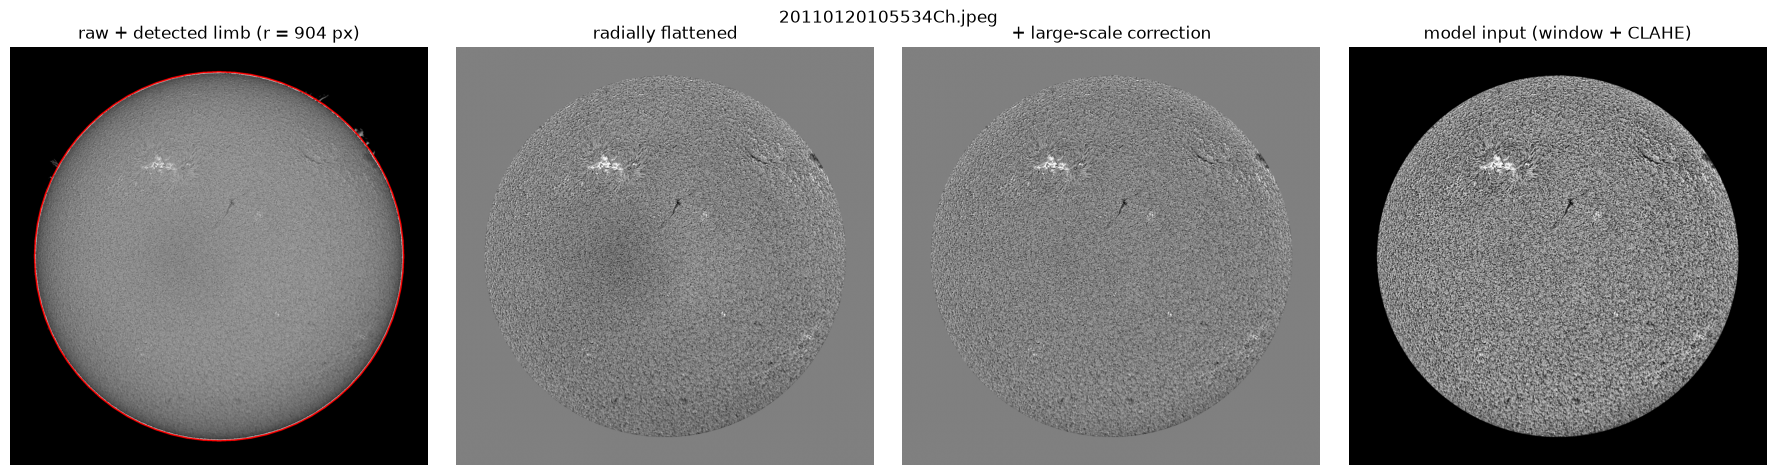

In [2]:
example = sorted(TEST_IMAGES.glob("*.jp*g"))[0]
pre = ImgPreProcess(example)
out = pre.run()
cx, cy, r = pre.disk

fig, axes = plt.subplots(1, 4, figsize=(18, 4.8))
raw = cv.cvtColor(pre.image_u8, cv.COLOR_GRAY2RGB)
cv.circle(raw, (round(cx), round(cy)), round(r), (255, 0, 0), 6)
axes[0].imshow(raw); axes[0].set_title(f"raw + detected limb (r = {r:.0f} px)")
axes[1].imshow(pre.stages["radial_flat"], cmap="gray", vmin=0.6, vmax=1.4); axes[1].set_title("radially flattened")
axes[2].imshow(pre.stages["flat"], cmap="gray", vmin=0.6, vmax=1.4); axes[2].set_title("+ large-scale correction")
axes[3].imshow(out, cmap="gray"); axes[3].set_title("model input (window + CLAHE)")
for ax in axes:
    ax.axis("off")
fig.suptitle(example.name)
plt.tight_layout()

Preprocess every test frame. A frame whose limb cannot be found would be missing from the submission, so failures are listed.

In [3]:
def preprocess_dir(src_files, dst):
    dst.mkdir(parents=True, exist_ok=True)
    failures = []
    for f in src_files:
        try:
            cv.imwrite(str(dst / f.name), ImgPreProcess(f).run())
        except DiskDetectionError as error:
            failures.append((f.name, str(error)))
    return failures

start = time.time()
test_files = sorted(TEST_IMAGES.glob("*.jp*g"))
failures = preprocess_dir(test_files, WORK / "processed_test")
print(f"{len(test_files) - len(failures)}/{len(test_files)} test frames preprocessed "
      f"in {time.time() - start:.0f} s; failures: {failures}")

180/180 test frames preprocessed in 99 s; failures: []


## 2. The model

FilaNet follows EdgeAttNet (Solomon et al., 2025): a U-Net whose bottleneck runs self-attention guided by an edge
map learned from the input, which replaces positional encodings. Our changes:

* every 3×3 convolution, encoder and decoder, is a **deformable** convolution (Dai et al., 2017), so the kernels can
  follow thin, curved filaments and barbs;
* six encoder stages, widths 32-64-128-256-384-512, so the bottleneck sees a 32×32 token grid of the full 2048 px frame;
* GroupNorm instead of BatchNorm (batch size 1 on full frames; training windows and full frames have different statistics);
* a second output channel predicting the filament **centreline**, used only as an auxiliary training target.

The weights are stored in four files (GitHub limits file size); `release.py` checks their SHA-256 and joins them.

In [4]:
model = load_released_model(ROOT / "weights", device)
n_params = sum(p.numel() for p in model.parameters())
print(f"FilaNet: {n_params / 1e6:.1f} M parameters, output channels: {model.head.out_channels} "
      "(0 = filament mask, used for the submission; 1 = centreline, auxiliary)")

FilaNet: 31.4 M parameters, output channels: 2 (0 = filament mask, used for the submission; 1 = centreline, auxiliary)


## 3. Probability map with test-time augmentation

The network was trained on all eight symmetries of the square (4 rotations × optional mirror). At test time each frame
is predicted in all eight orientations, each answer is turned back, and the eight probability maps are averaged.

12.0 s for one frame with 8 views


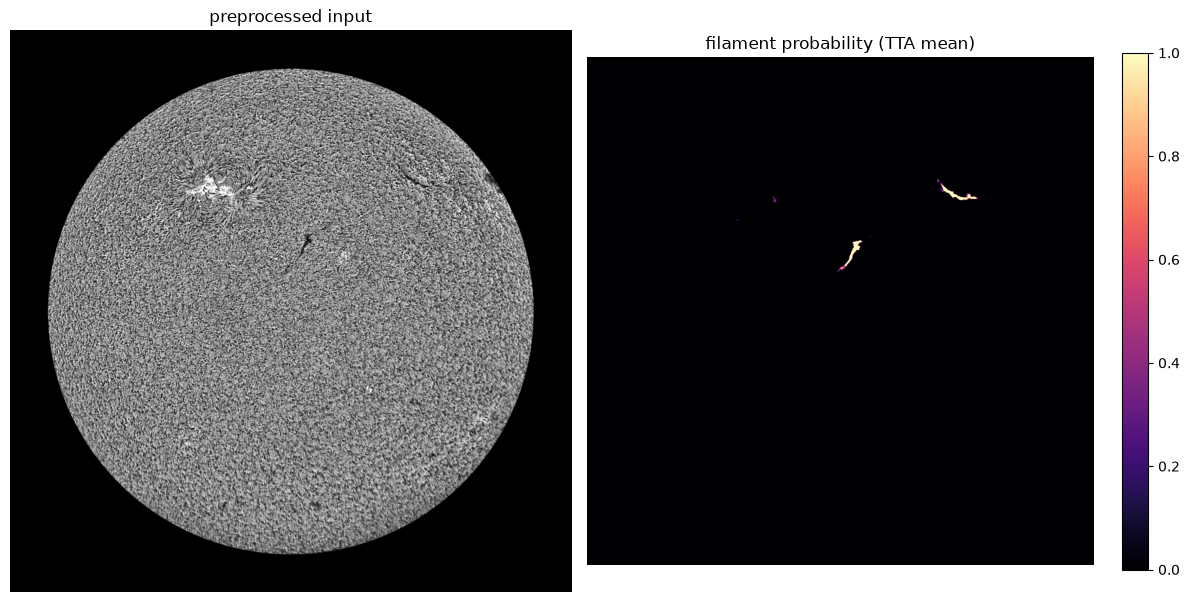

In [5]:
processed_example = WORK / "processed_test" / example.name
image = torch.from_numpy(cv.imread(str(processed_example), cv.IMREAD_GRAYSCALE)).float().div(255)[None, None].to(device)
with torch.no_grad():
    start = time.time()
    probability = predict_probability(model, image, tta=TTA).cpu().numpy()
print(f"{time.time() - start:.1f} s for one frame with {'8' if TTA else '1'} views")

fig, axes = plt.subplots(1, 2, figsize=(12, 6))
axes[0].imshow(image[0, 0].cpu(), cmap="gray"); axes[0].set_title("preprocessed input")
im = axes[1].imshow(probability, cmap="magma", vmin=0, vmax=1); axes[1].set_title("filament probability (TTA mean)")
plt.colorbar(im, ax=axes[1], fraction=0.046)
for ax in axes:
    ax.axis("off")
plt.tight_layout()

## 4. From probabilities to filaments

The competition scores each filament separately (Panoptic Quality at IoU > 0.5), so the probability map is cut into
instances:

* **Hysteresis.** A filament is a connected region (8-connectivity) of pixels ≥ `low` = 0.7 that contains at least
  one pixel ≥ `high` = 0.99. The confident core decides *whether* there is a filament; the lower threshold decides
  *how far* it extends.
* **Minimum area.** Regions under 300 px are dropped.
* **Fragment merging.** The network sometimes breaks one filament into a chain of pieces, none of which alone reaches
  IoU 0.5. Pieces within 10 px of each other are joined into one filament (only their own pixels are kept).
* Each filament becomes one row: `<image>_<n>`, COCO run-length encoding.

2 pieces -> 2 filaments after merging pieces <= 10 px apart


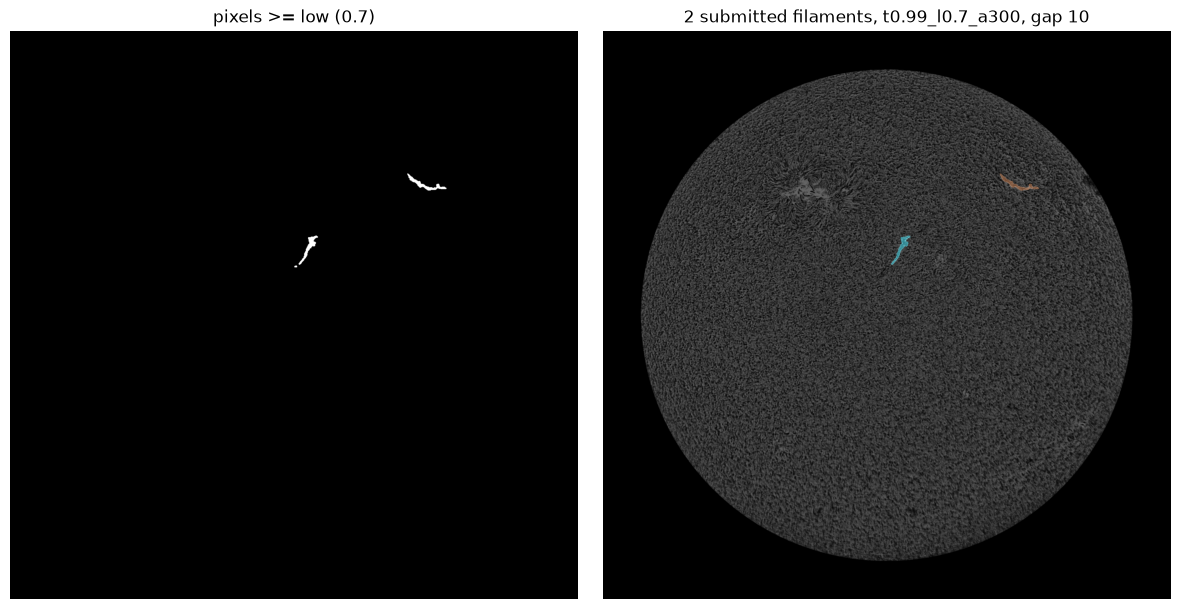

In [6]:
instances = probability_to_instances(probability, POINT, MERGE_GAP)
unmerged = probability_to_instances(probability, POINT, 0)
print(f"{len(unmerged)} pieces -> {len(instances)} filaments after merging pieces <= {MERGE_GAP} px apart")

rng = np.random.default_rng(0)
colour = np.zeros((*probability.shape, 3))
for instance in instances:
    colour[instance.astype(bool)] = rng.uniform(0.3, 1.0, 3)
fig, axes = plt.subplots(1, 2, figsize=(12, 6))
axes[0].imshow(probability >= POINT[2], cmap="gray"); axes[0].set_title(f"pixels >= low ({POINT[2]})")
axes[1].imshow(image[0, 0].cpu(), cmap="gray"); axes[1].imshow(colour, alpha=0.6)
axes[1].set_title(f"{len(instances)} submitted filaments, {point_name(POINT)}, gap {MERGE_GAP}")
for ax in axes:
    ax.axis("off")
plt.tight_layout()

## 5. The whole test set → `submission.csv`

In [7]:
def predict_directory(files, out_csv=None):
    """Submission rows for preprocessed frames; also returns the per-frame instance lists."""
    rows, per_image = [], {}
    start = time.time()
    for n, f in enumerate(files, start=1):
        x = torch.from_numpy(cv.imread(str(f), cv.IMREAD_GRAYSCALE)).float().div(255)[None, None].to(device)
        with torch.no_grad():
            p = predict_probability(model, x, tta=TTA).cpu().numpy()
        per_image[f.stem] = probability_to_instances(p, POINT, MERGE_GAP)
        rows.extend(rows_from_instances(f.stem, per_image[f.stem]))
        if n % 20 == 0 or n == len(files):
            print(f"  {n}/{len(files)} frames, {len(rows)} filaments, {time.time() - start:.0f} s")
    if out_csv is not None:
        write_submission(rows, out_csv)
    return rows, per_image

test_processed = sorted((WORK / "processed_test").glob("*.jp*g"))
rows, _ = predict_directory(test_processed, WORK / "submission.csv")
print(f"wrote {WORK / 'submission.csv'}: {len(rows)} filaments over {len(test_processed)} frames")

  20/180 frames, 156 filaments, 264 s


  40/180 frames, 344 filaments, 543 s


  60/180 frames, 520 filaments, 821 s


  80/180 frames, 747 filaments, 1103 s


  100/180 frames, 955 filaments, 1386 s


  120/180 frames, 1093 filaments, 1667 s


  140/180 frames, 1184 filaments, 1948 s


  160/180 frames, 1247 filaments, 2231 s


  180/180 frames, 1350 filaments, 2511 s
wrote D:\Personal\solar_filament_competition\prom_seg\final_submission\work\submission.csv: 1350 filaments over 180 frames


Check the reproduction against the file we submitted (`submitted/submission_filanet7.csv`). Exact equality is
expected on the same software stack; a different GPU or library version may move a handful of boundary pixels, so the
per-frame agreement of the predicted masks is reported as well.

In [8]:
ours = pd.read_csv(WORK / "submission.csv")
submitted = pd.read_csv(ROOT / "submitted" / "submission_filanet7.csv")
print(f"rows: reproduced {len(ours)}, submitted {len(submitted)}")
print("identical files:", ours.equals(submitted))

def union_masks(df):
    masks = {}
    for fid, rle in zip(df.filament_id, df.segmentation_rle):
        stem = fid.rsplit("_", 1)[0]
        m = mask_util.decode({"size": [2048, 2048], "counts": rle.encode()})
        masks[stem] = np.maximum(masks.get(stem, 0), m)
    return masks

a, b = union_masks(ours), union_masks(submitted)
dice = [2 * (a[s] & b[s]).sum() / (a[s].sum() + b[s].sum()) for s in a.keys() & b.keys()]
print(f"frames with filaments: reproduced {len(a)}, submitted {len(b)}; "
      f"mean per-frame Dice between the two {np.mean(dice):.6f} (min {np.min(dice):.6f})")

rows: reproduced 1350, submitted 1350
identical files: True


frames with filaments: reproduced 179, submitted 179; mean per-frame Dice between the two 1.000000 (min 1.000000)


## 6. Score on our validation photographs

The training annotations were split by **photograph** (seed 0): 601 photographs for training, 106 (175
annotator-images, 1387 filaments) held out. A photograph annotated by several people stays on one side of the split,
and is predicted once and scored against every annotator, as on the leaderboard. Here the full pipeline above is run
on those 106 held-out photographs and scored with our port of the organisers' PQ code.

Note the operating point was itself chosen on these photographs, so this figure is slightly optimistic;
split-half cross-validation in the report puts the selection-free estimate at 0.386.

In [9]:
def score(gt_df, pred_df):
    """PQ, SQ, RQ and counts, pooled over annotator-images as in the competition metric."""
    iou_sum, tp, fp, fn = 0.0, 0, 0, 0
    for row in overlap_table(gt_df, pred_df).itertuples(index=False):
        if row.n_gt == 0:
            fp += row.n_pred; continue
        if row.n_pred == 0:
            fn += row.n_gt; continue
        hits = row.iou_matrix > IOU_THRESHOLD
        iou_sum += float(row.iou_matrix[hits].sum()); tp += int(hits.sum())
        fp += int((hits.sum(dim=0) == 0).sum()); fn += int((hits.sum(dim=1) == 0).sum())
    pq = iou_sum / (tp + 0.5 * fp + 0.5 * fn)
    return dict(PQ=pq, SQ=iou_sum / tp, RQ=tp / (tp + 0.5 * fp + 0.5 * fn), TP=tp, FP=fp, FN=fn)

if VALIDATE:
    import json
    all_ids = sorted(img["id"] for img in json.loads(ANNOTATIONS.read_text())["images"])
    _, val_ids = split_by_image(all_ids, val_fraction=0.15, seed=0)
    val_photos = sorted({i.split("-", 1)[1] for i in val_ids})
    files = [f for f in TRAIN_IMAGES.glob("*.jp*g") if f.stem in val_photos]
    print(f"{len(val_ids)} annotator-images over {len(val_photos)} photographs")
    print("preprocessing failures:", preprocess_dir(files, WORK / "processed_val"))
    val_rows, val_instances = predict_directory(sorted((WORK / "processed_val").glob("*.jp*g")))
    gt_df = gt_df_from_coco(ANNOTATIONS, image_ids=set(val_ids))
    pred_df = pd.DataFrame(val_rows, columns=["filament_id", "segmentation_rle"])
    result = score(gt_df, pred_df)
    print({k: round(v, 4) if isinstance(v, float) else v for k, v in result.items()})

175 annotator-images over 106 photographs


preprocessing failures: []


  20/106 frames, 158 filaments, 285 s


  40/106 frames, 350 filaments, 580 s


  60/106 frames, 570 filaments, 874 s


  80/106 frames, 763 filaments, 1176 s


  100/106 frames, 861 filaments, 1471 s


  106/106 frames, 891 filaments, 1560 s


{'PQ': 0.3911, 'SQ': 0.6578, 'RQ': 0.5946, 'TP': 839, 'FP': 596, 'FN': 548}


One validation photograph: what the annotators drew, and what the pipeline submits.

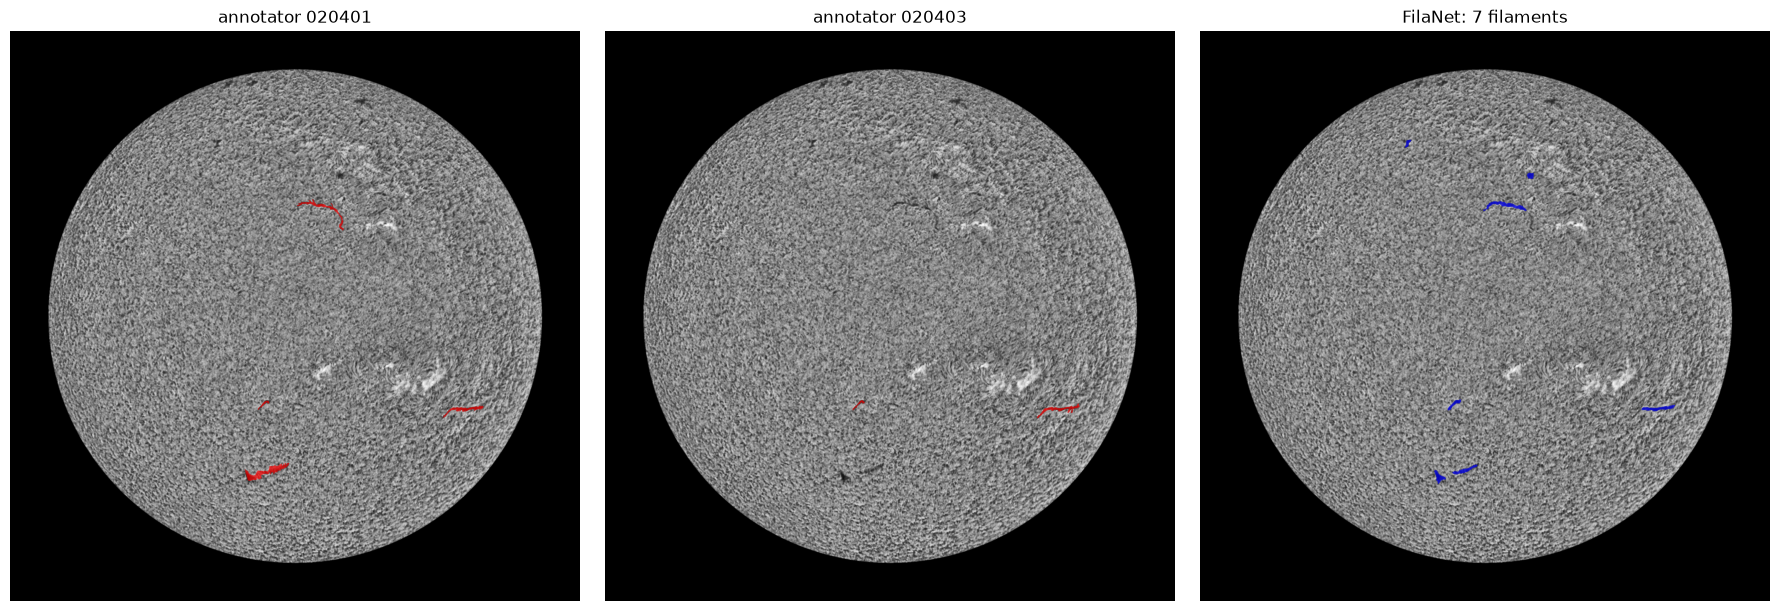

In [10]:
if VALIDATE:
    # the first held-out photograph that more than one person annotated
    photo = next(p for p in val_photos if sum(i.endswith(p) for i in val_ids) >= 2)
    img = cv.imread(str(WORK / "processed_val" / f"{photo}.jpeg"), cv.IMREAD_GRAYSCALE)
    annotators = [i for i in val_ids if i.endswith(photo)]
    keys = gt_df.filament_id.str.rsplit("_", n=1).str[0]
    fig, axes = plt.subplots(1, len(annotators) + 1, figsize=(6 * (len(annotators) + 1), 6))
    for ax, annotator_image in zip(axes, annotators):
        gt = np.zeros(img.shape, np.uint8)
        for rle in gt_df.segmentation_rle[keys == annotator_image]:
            gt |= mask_util.decode({"size": [2048, 2048], "counts": rle.encode()})
        ax.imshow(img, cmap="gray"); ax.imshow(np.ma.masked_equal(gt, 0), cmap="autumn", alpha=0.7)
        ax.set_title(f"annotator {annotator_image.split('-')[0]}")
    pred = np.zeros(img.shape, np.uint8)
    for m in val_instances[photo]:
        pred |= m
    axes[-1].imshow(img, cmap="gray"); axes[-1].imshow(np.ma.masked_equal(pred, 0), cmap="winter", alpha=0.7)
    axes[-1].set_title(f"FilaNet: {len(val_instances[photo])} filaments")
    for ax in axes:
        ax.axis("off")
    plt.tight_layout()

## 7. Training (not run here)

The released weights come from two training stages, both with `src/train.py` on preprocessed training frames
(`python src/img_prepro_v2.py data/MAGFiLO_1.0_Kaggle_2026/train/train_images work/processed_train`). The split is the
seed-0 photograph split above. Each stage takes days on one 16 GB GPU, so this cell only prints the commands.

* **Stage 1 (filanet6), 30 epochs.** 512×512 random windows, 70% of them centred on a filament pixel, batch 8, random
  rotation/mirroring, target = union of the photograph's annotators. Loss: 0.7·(1 − Tversky, β = 0.7) + 0.3·(1 − clDice)
  + BCE. AdamW, lr 1e-4, weight decay 0.01, one warm-up epoch then cosine decay to 1e-6. These settings are
  reconstructed from that run's log and checkpoint.
* **Stage 2 (filanet7), 3 epochs** from stage 1's weights, on whole 2048 px frames (batch 1, 4 accumulated steps),
  lr 3e-5 with cosine decay, adding the centreline output (weight 0.5) and up-weighting the pixels of small filaments in
  the BCE term. The checkpoint with the best validation PQ (epoch 3) is the one released.

In [11]:
RUN_TRAINING = False
common = (f"--images work/processed_train --annotations {ANNOTATIONS}")
stage1 = f"python src/train.py {common} --out runs/filanet6 --crop 512 --batch-size 8 --accumulation 1 --epochs 30 --val-every 3"
stage2 = (f"python src/train.py {common} --out runs/filanet7 --init runs/filanet6/best.pt "
          "--spine-weight 0.5 --size-balance --lr 3e-5 --warmup-epochs 0.1 --epochs 3 --ema 0.99")
print(stage1, stage2, sep="\n\n")
if RUN_TRAINING:
    import subprocess
    subprocess.run(stage1, shell=True, check=True)
    subprocess.run(stage2, shell=True, check=True)

python src/train.py --images work/processed_train --annotations D:\Personal\solar_filament_competition\prom_seg\filament-segmentation-2026\MAGFiLO_1.0_Kaggle_2026\train\MAGFiLO_1.0_Annotations_kaggle2026_train.json --out runs/filanet6 --crop 512 --batch-size 8 --accumulation 1 --epochs 30 --val-every 3

python src/train.py --images work/processed_train --annotations D:\Personal\solar_filament_competition\prom_seg\filament-segmentation-2026\MAGFiLO_1.0_Kaggle_2026\train\MAGFiLO_1.0_Annotations_kaggle2026_train.json --out runs/filanet7 --init runs/filanet6/best.pt --spine-weight 0.5 --size-balance --lr 3e-5 --warmup-epochs 0.1 --epochs 3 --ema 0.99
